In [1]:
%matplotlib inline
import sys
import numpy as np
import matplotlib.pyplot as plt
import control as ct
sys.path.append("../src")
from metrics import step_metrics

K, tau = 1, 0.5
G = ct.tf([K], [tau, 1])

def make_pid(Kp, Ki=0.0, Kd=0.0):
    C = ct.tf([Kp], [1])
    if Ki != 0:
        C = C + ct.tf([Ki], [1, 0])
    if Kd != 0:
        C = C + ct.tf([Kd, 0], [1])
    return C

In [2]:
L = 0.05                                  # dead time in seconds
num, den = ct.pade(L, 3)                  # 3rd-order Pade approximation of a delay
Gd = G * ct.tf(num, den)                  # motor with dead time

L estimated: 0.05  (model value 0.05)
T estimated: 0.522  (model value 0.5)


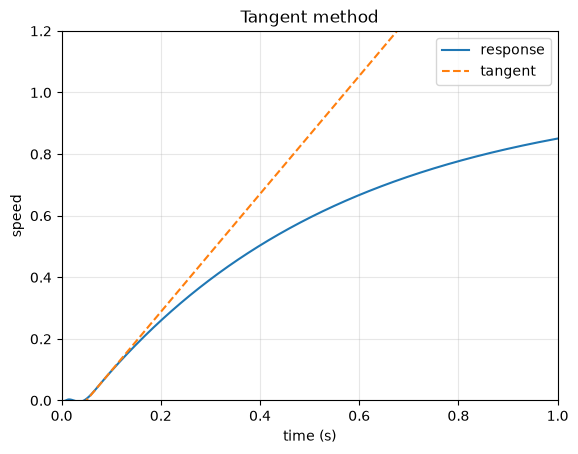

In [3]:
t = np.linspace(0, 5, 5000)
t, y = ct.step_response(Gd, t)

slope = np.gradient(y, t)
i = np.argmax(slope)                              # steepest point
t_L = t[i] - y[i] / slope[i]                      # tangent crosses zero: this is L
t_K = t[i] + (K - y[i]) / slope[i]                # tangent reaches K
L_est, T_est = t_L, t_K - t_L
print("L estimated:", round(L_est, 3), " (model value 0.05)")
print("T estimated:", round(T_est, 3), " (model value 0.5)")

plt.plot(t, y, label="response")
plt.plot(t, y[i] + slope[i] * (t - t[i]), "--", label="tangent")
plt.ylim(0, 1.2); plt.xlim(0, 1)
plt.xlabel("time (s)"); plt.ylabel("speed"); plt.legend(); plt.grid(True, alpha=0.3)
plt.title("Tangent method"); plt.show()

In [4]:
Kp_zn = 1.2 * T_est / (K * L_est)
Ti = 2 * L_est
Td = 0.5 * L_est
Ki_zn = Kp_zn / Ti
Kd_zn = Kp_zn * Td
print(f"Z-N gains: Kp={Kp_zn:.2f}, Ki={Ki_zn:.2f}, Kd={Kd_zn:.3f}")

Z-N gains: Kp=12.58, Ki=126.31, Kd=0.313


manual PI   OS=  4.1%  rise=0.096s  settle=0.303s  sse=-0.000
manual PID  OS= 40.7%  rise=0.071s  settle=0.944s  sse=0.000
Z-N         OS= 79.1%  rise=0.060s  settle=0.458s  sse=0.000


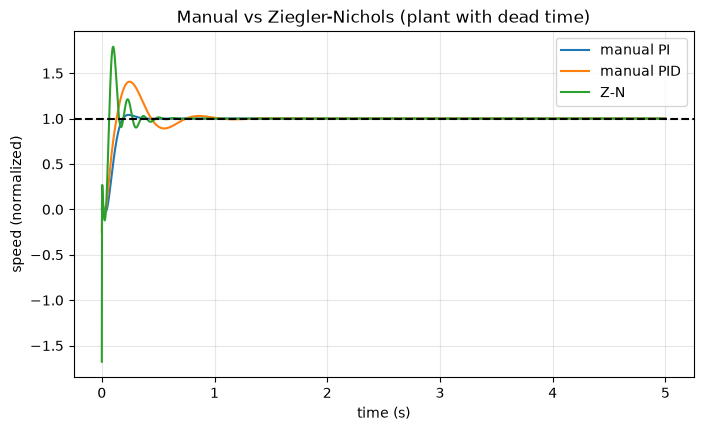

In [5]:
sets = {"manual PI": (5, 10, 0),
        "manual PID": (5, 50, 0.1),
        "Z-N": (Kp_zn, Ki_zn, Kd_zn)}

t = np.linspace(0, 5, 5000)
plt.figure(figsize=(8, 4.5))
for name, (Kp, Ki, Kd) in sets.items():
    T = ct.feedback(make_pid(Kp, Ki, Kd) * Gd, 1)
    t, y = ct.step_response(T, t)
    m = step_metrics(t, y)
    print(f"{name:11} OS={m['overshoot']:5.1f}%  rise={m['rise_time']:.3f}s  "
          f"settle={m['settling_time']:.3f}s  sse={m['sse']:.3f}")
    plt.plot(t, y, label=name)
plt.axhline(1, ls="--", color="k")
plt.xlabel("time (s)"); plt.ylabel("speed (normalized)")
plt.title("Manual vs Ziegler-Nichols (plant with dead time)")
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig("../plots/zn_vs_manual.png", dpi=150); plt.show()

Z-N rises fastest and overshoots most, because the method tunes for a quarter-decay response (each oscillation peak is a quarter of the previous one), and that is aggressive. Use your own numbers.

In [6]:
%%writefile ../src/plants.py
import numpy as np

def simulate(Kp, Ki, Kd, setpoint=10.0, t_end=3.0, K=1.0, tau=0.5, dt=0.01,
             umax=12.0, dz=1.5, fric=0.5, q=0.05, noise=0.02, delay=True, seed=0):
    """Closed-loop simulation of a motor with real-world effects.
    Set umax=np.inf, dz=0, fric=0, q=0, noise=0, delay=False to switch effects off."""
    rng = np.random.default_rng(seed)
    n = int(t_end / dt)
    t = np.arange(n) * dt
    y = np.zeros(n)                 # true motor speed
    u_log = np.zeros(n)             # controller output
    omega = 0.0                     # motor speed state
    integral = 0.0
    prev_e = 0.0
    u_prev = 0.0

    for k in range(n):
        # --- sensor: noise, then quantization (smallest step the encoder can see)
        meas = omega + (rng.normal(0, noise) if noise > 0 else 0.0)
        if q > 0:
            meas = np.round(meas / q) * q

        # --- controller (discrete PID)
        e = setpoint - meas
        integral += e * dt
        d = 0.0 if k == 0 else (e - prev_e) / dt
        prev_e = e
        u = Kp * e + Ki * integral + Kd * d
        u = np.clip(u, -umax, umax)             # saturation
        u_log[k] = u

        # --- one-sample delay between controller and motor
        u_apply = u_prev if delay else u
        u_prev = u

        # --- deadband and friction (friction simplified as lost drive)
        if abs(u_apply) < dz:
            u_eff = 0.0
        else:
            u_eff = u_apply - fric * np.sign(u_apply)

        # --- motor dynamics: Euler integration, 10 sub-steps of 1 ms per sample
        for _ in range(10):
            omega += (-omega + K * u_eff) / tau * (dt / 10)
        y[k] = omega

    return t, y, u_log

Writing ../src/plants.py


In [7]:
import importlib, plants
importlib.reload(plants)
from plants import simulate

off = dict(umax=np.inf, dz=0, fric=0, q=0, noise=0, delay=False)

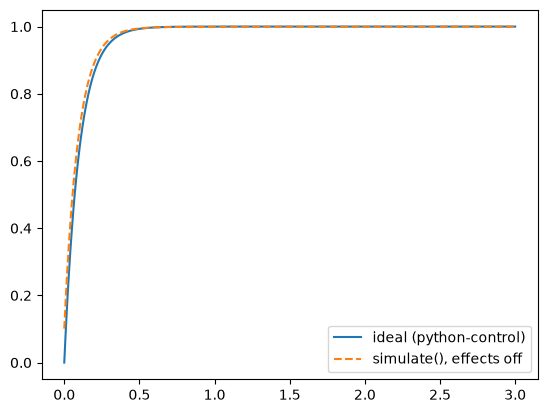

In [8]:
# 1. All effects off must match the ideal model
T = ct.feedback(make_pid(5, 10, 0) * G, 1)
ti, yi = ct.step_response(T, np.linspace(0, 3, 300))
t, y, u = simulate(5, 10, 0, **off)
plt.plot(ti, yi, label="ideal (python-control)")
plt.plot(t, y / 10, "--", label="simulate(), effects off")
plt.legend(); plt.show()

In [9]:
# 2. A command inside the deadband produces no motion
t, y, u = simulate(0.1, 0, 0, setpoint=10, **{**off, "dz": 1.5})
print("max speed with tiny command:", y.max())   # Kp*e = 1.0 < 1.5, so expect 0.0

max speed with tiny command: 0.0


In [10]:
# 3. A big command reaches a lower speed than the ideal prediction
t, y, u = simulate(5, 0, 0, setpoint=10, t_end=3)
print("speed with real effects:", round(y[-1], 2), " ideal P-only value:", round(10 * 5 / 6, 2))

speed with real effects: 8.25  ideal P-only value: 8.33


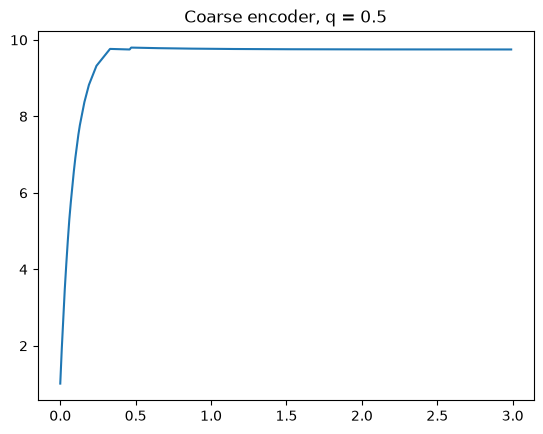

In [11]:
t, y, u = simulate(5, 10, 0, **{**off, "q": 0.5})
plt.plot(t, y); plt.title("Coarse encoder, q = 0.5"); plt.show()

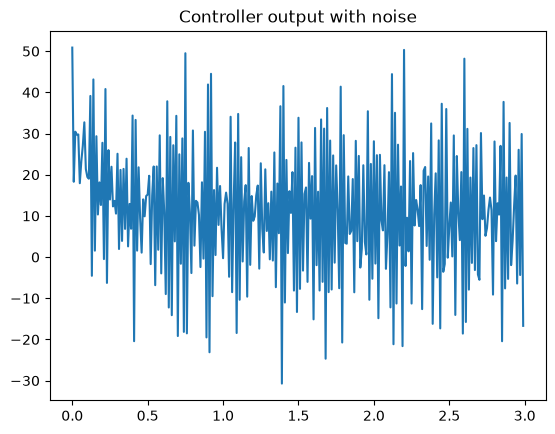

In [12]:
t, y, u = simulate(5, 10, 0.3, **{**off, "noise": 0.2})
plt.plot(t, u); plt.title("Controller output with noise"); plt.show()

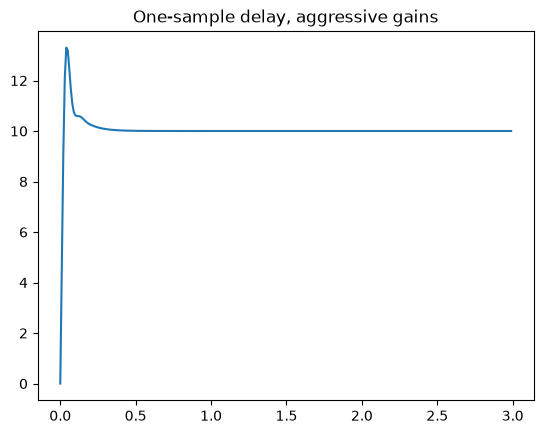

In [13]:
t, y, u = simulate(20, 200, 0, **{**off, "delay": True})
plt.plot(t, y); plt.title("One-sample delay, aggressive gains"); plt.show()